**INTRODUCCIÓN**

En este trabajo se simulo un conversor analógico digital (ADC) de B bits, con rango +/- VFS. Se tomó como señal de entrada una senoidal con ruido y se la muestreó a una frecencia 8fs) de 1000Hz. Con los resulados se analizó como la resolución del conversor interactua con el ruido analógico presente en la seal de entrada, afectando la relación señal ruido (SNR) de la señal digitalizada y cuantizada 

En primer lugar se iportaron laslibrerias necesarias y se definieron las variables correspondientes. Además se utilizó una "semilla" de numPy para que la libreria comienze siempre desde su mismo indice de secuencia interna, permitiendo que el ruido adicionado a la senoidal al variar B y kn (comolo pedido en el inciso 2) sea igual , perimitiendo que la comparación entre casos sea mas certera.

Se estableció N =1000 muestras de forma que la resolución especral $\Delta f = \frac{f_s}{N}$, por lo cual se pueden distingúir frecuencias separadas poral menos 1Hz al realizar la DFT. Además como se pide una frecuencia de señal arbtraria $\frac{f_s}{N}$ se tomó k = 1. La amplitud se calculó a partir de la varianza unitaria peidida, dando $A = \sqrt{2}$. Por su parte, el rango del ADC definido por la conigna genera que la señal no ocupe todo el rango dinámico del conversor. También se definio un vector para los valores de B y Kn pedidos por el enunciado.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

#variables de muestreo
fs  = 1000 # Hz
N   = 1000 # muestras
n=np.arange(N)

#variables de la señal
vmax=np.sqrt(2)
ph=0
dc=0
k=1

#relacion señal ruido
kns=[1/10, 1, 10]

#variables del cuantizador
B=[4, 8, 16]
Vfs = 2 # VoltS


Para poder colectar los resultados se definió un vector "resultados" al cual se le agregaron los resultados para cada caso analizado.

Se utilizaron dos bucles for, uno para cada B y uno para cada Kn, con el fin de analizar todas las combinaciones posible

Para cada caso se calculo el paso de cuantización como : $q = \frac{2 Vfs}{2^B}$, el cual acota el error intrucido en cada paso de cuantización. Además, este error puede aproximarse (siempre y cuando que el paso de cuantización sea lo suficientemente pequeño respecto a la amplitud de la señal y que esta varíe atravesando múltiples niveles de cuantización) como ruido de distribuició uniforme en $\left[ -\frac{q}{2}, \frac{q}{2} \right]$, con potencia $P_q = \frac{q^2}{12}$. Luego, se calcula la potencia del ruido agregado con respecto al ruido de cuantización teórico como $P_n = k_n P_q$. Para la señal de entrada, se genero la senoidal y el ruido normal agregado en base a la potencia de ruido calculada previamente y se sumaron. 

La salida del ADC se calucló como $\text{np.round}\left(\frac{x_{\text{senruido}}}{q}\right) \cdot q$, lo cual en primer lugar normaliza la señal en q y luego al realizar el redondeo se "elige" el escalón de cuantizació correspondiente. Luego al multiplicar por q se obtiene el valor cuantizado en sus unidades físicas originales. Este proceso introduce un error de cuantización calculado como $e_{\text{cuant}} = x_{\text{adc}} - x_{\text{senruido}}$, y el error total sobe la señal limpia se calculo como $e_{\text{tot}} = x_{\text{adc}} - x_{\text{sen}}$. En base a esto se calcularon las potencas reales de las señal senoidal y del error total introducido para asi calcular los SNR medido y real y asi poder compararlos entre si. 

Se calcularon las DFT para la señal de entrada y el ruido de cuantización calculado para poder analizarlos en el dominio espectral. Además, para el ruido de cuantización, se calculo su autocorrelación para poder analizar si se observa un patrón periódico que muestre una falta de aletoreidad en este, y, se realizo el teste de Kolmogorov Smirnov para el p-valor. 

Por último, para cada caso, se añadieron los datos obenidos al vector resultados y se realizaron los graficos correspondientes (entrada y salida del ADC, FFT de la entrada y la salida del ADC, y autocorrelación del ruido de cuantización)

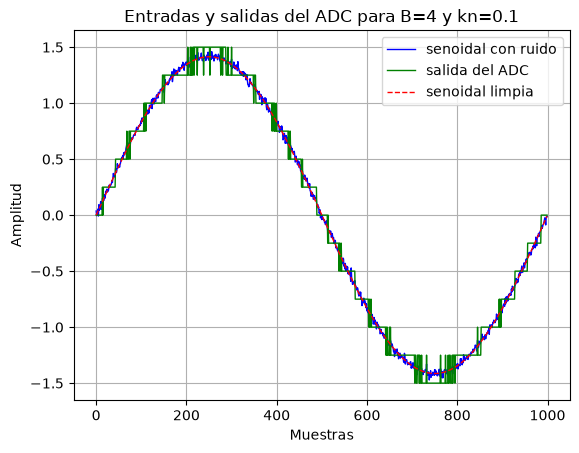

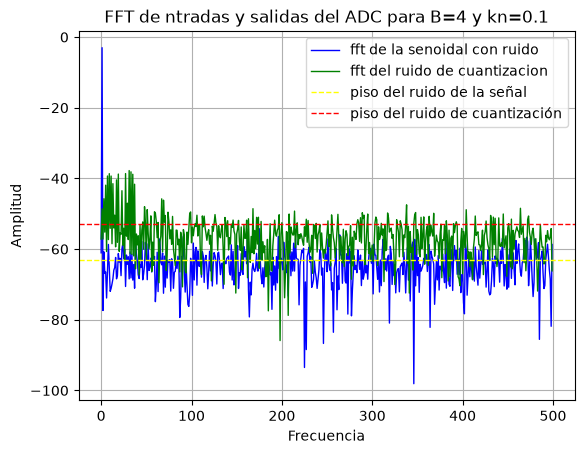

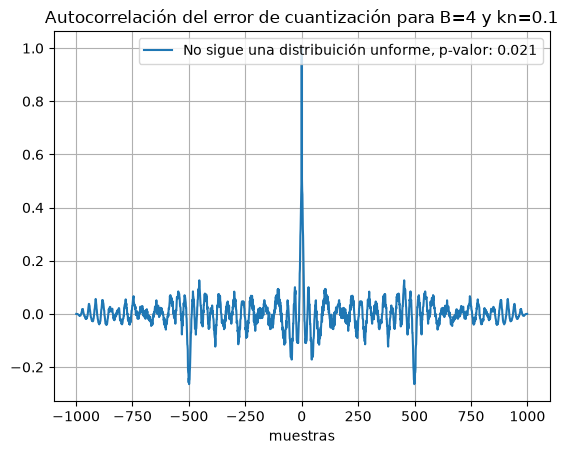

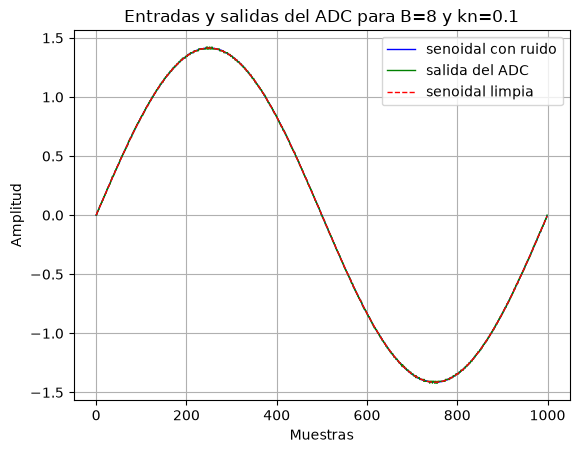

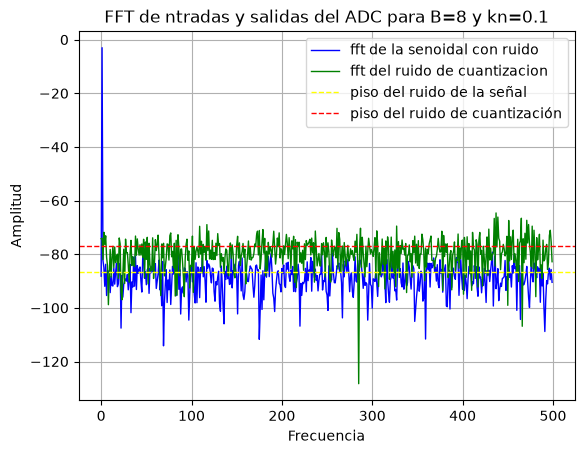

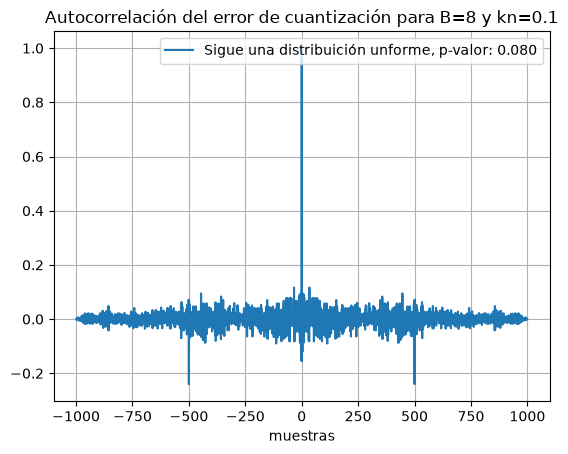

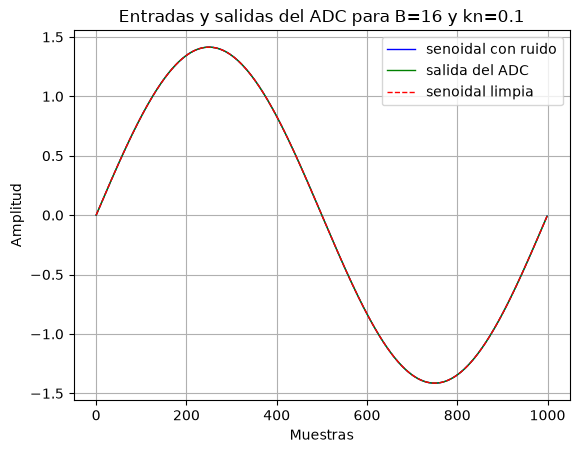

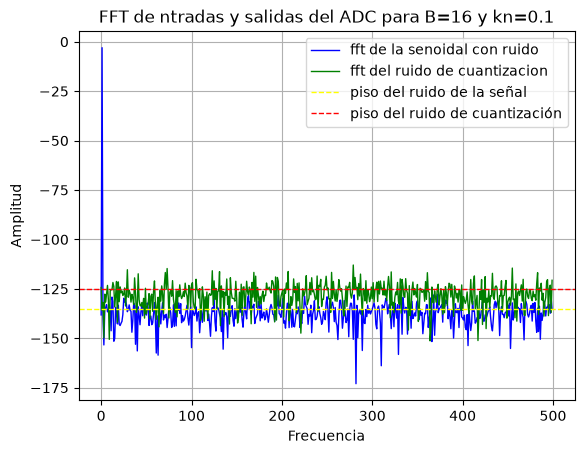

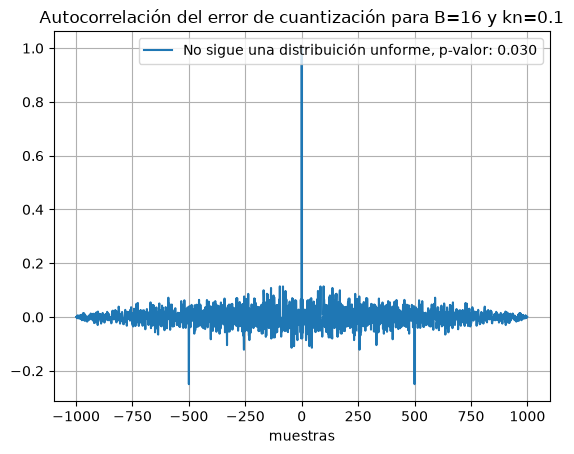

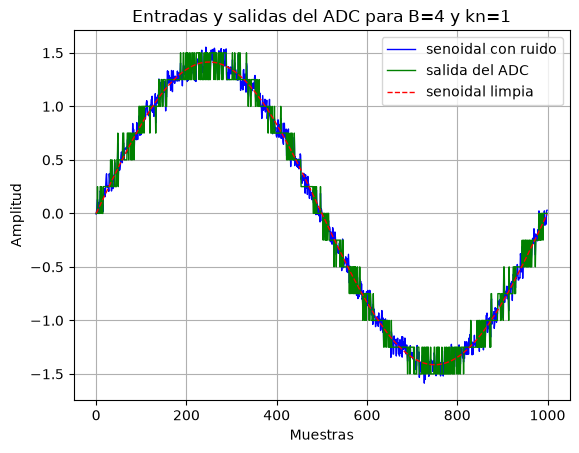

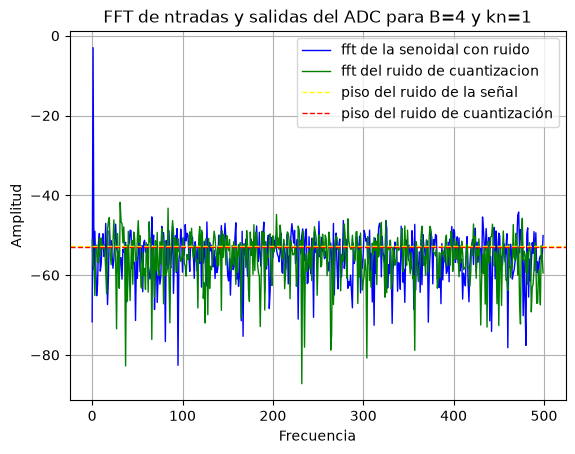

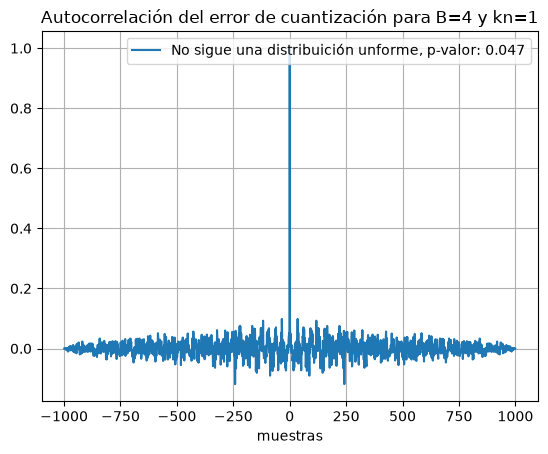

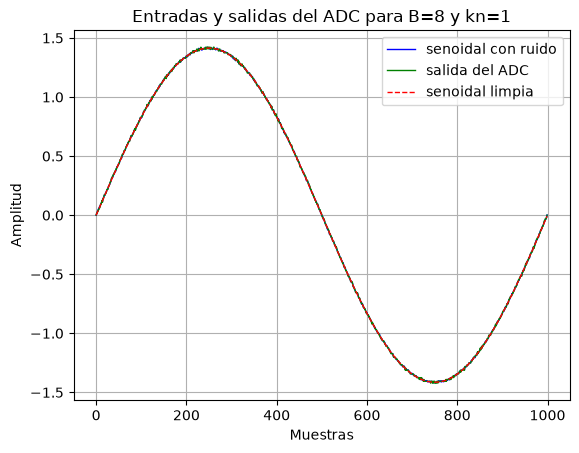

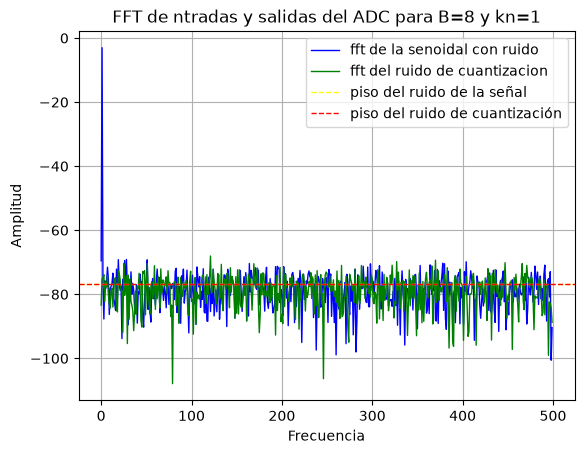

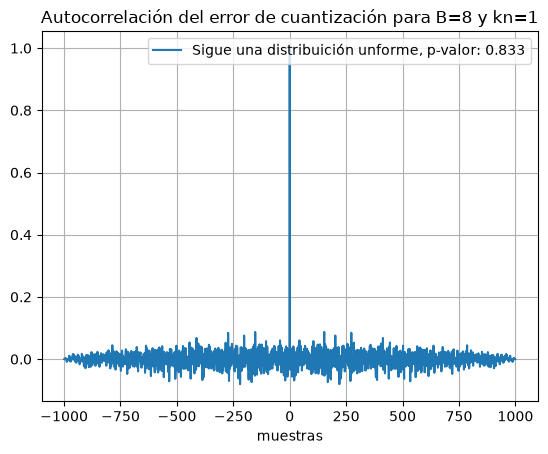

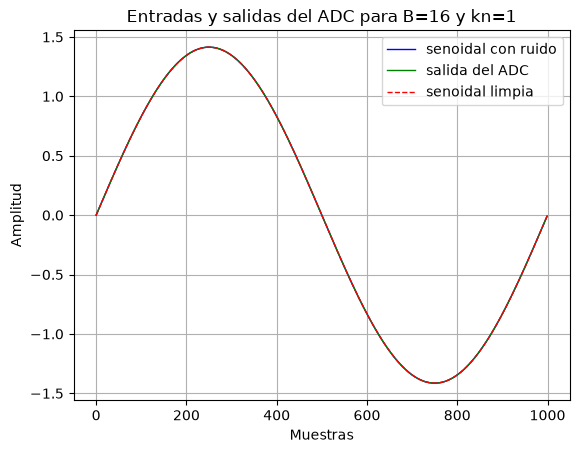

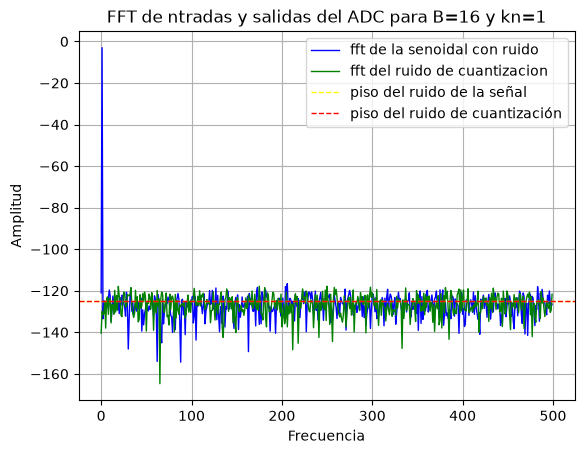

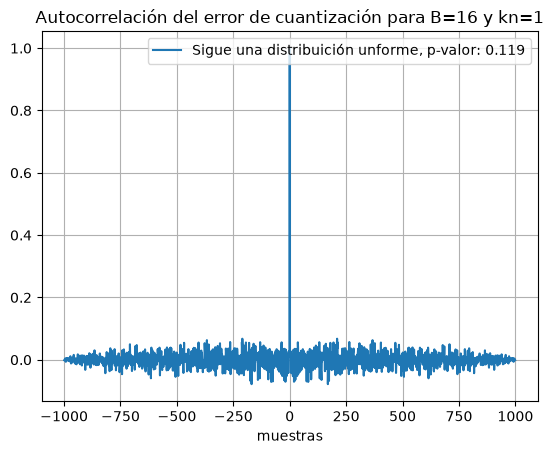

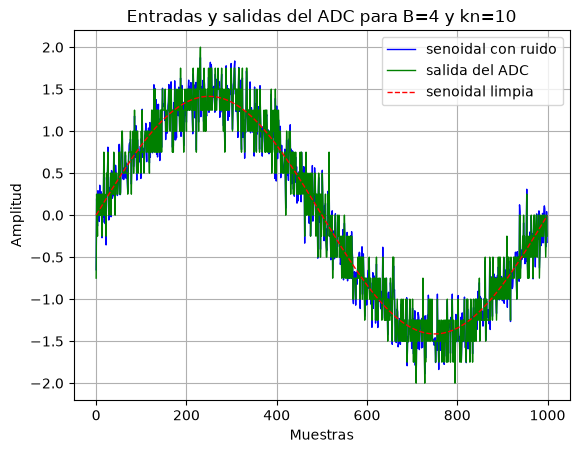

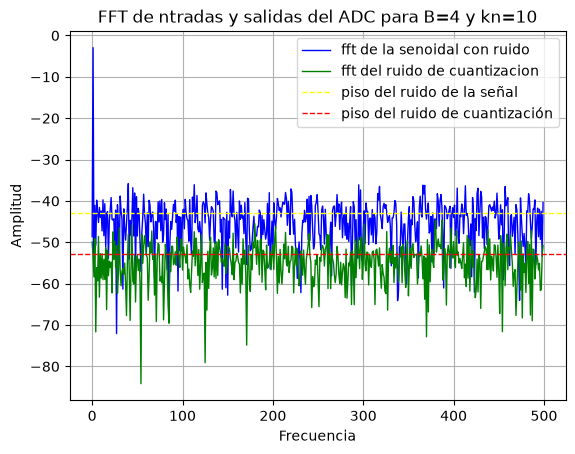

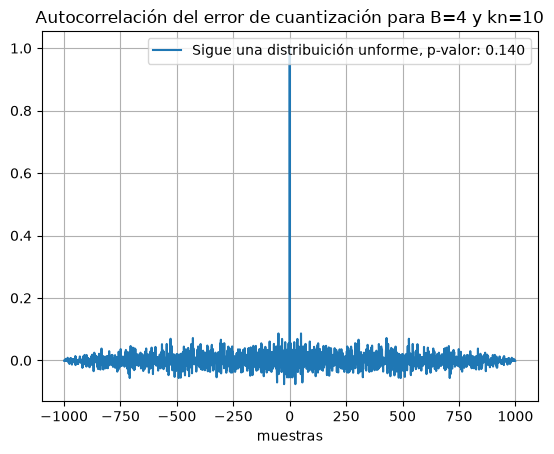

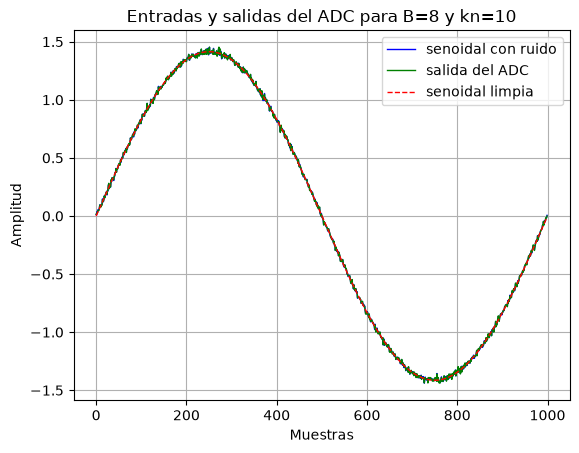

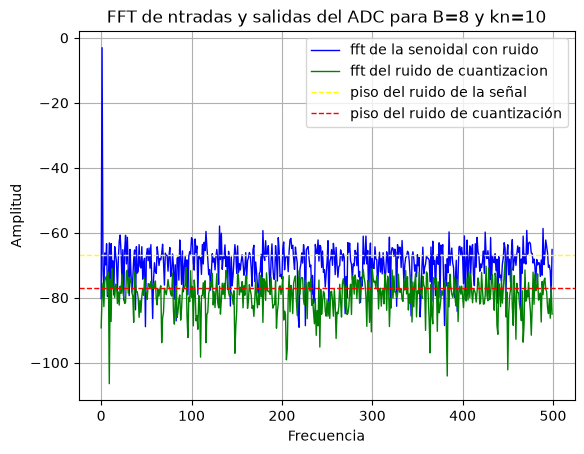

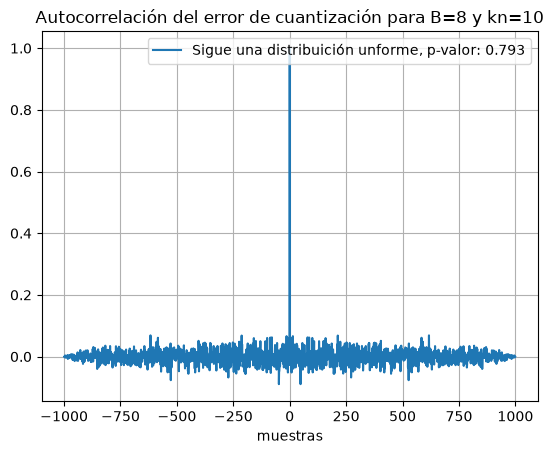

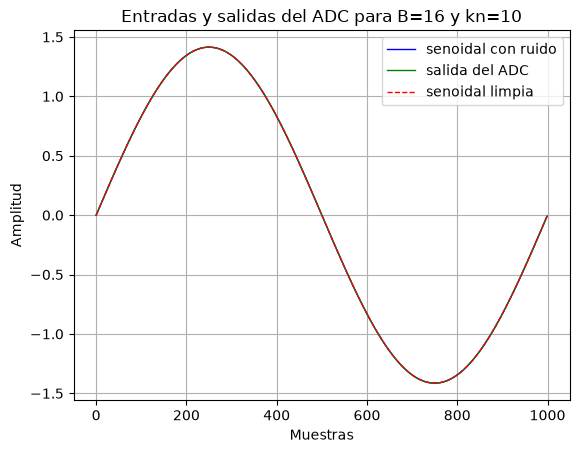

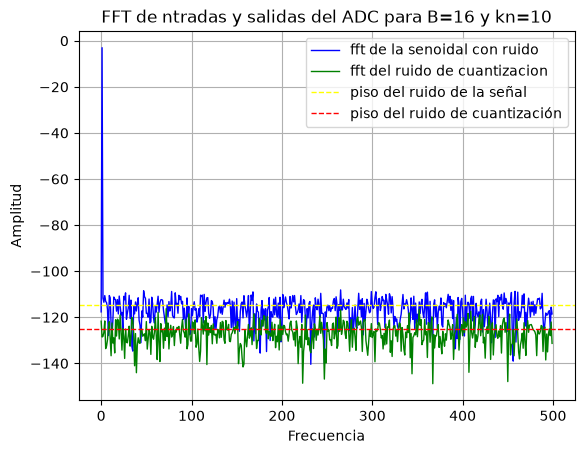

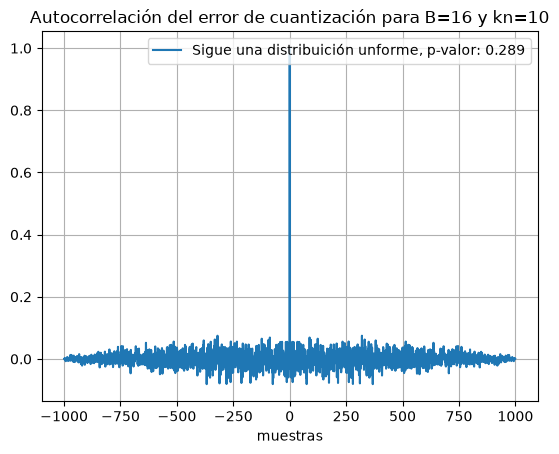

In [14]:
resultados = []
np.random.seed(1)
for kn in kns:
    for b in B:

        q  = 2*Vfs/2**b  # paso de cuantización
        Pq = q**2/12  # ruido de cuantización teórico
        Pn = kn*Pq  # ruido analógico de la señal necesario para cumplir con kn
        #generola senoidal
        xsen = vmax*np.sin(k*2*np.pi*n/N + ph) + dc
        ruido = np.random.normal(0, np.sqrt(Pn), N)
        xsenruido=xsen+ruido

        xadc = np.round(xsenruido/q)*q  # salida del ADC
        
        errortot = xadc - xsen  
        errorcuant= xadc- xsenruido
        
        
        Ps = np.var(xsen)
        Pe  = np.var(errortot)
        snr_medido  = 10*np.log10(Ps/Pe)
        snr_teorico = 10*np.log10(Ps/(Pq*(1+kn)))
        
        #ffts
        FF= np.arange(N//2)*fs/N #vector de frecuencias
        
        #para la senoidal con ruido
        ffty=np.fft.fft(xsenruido)[:N//2]
        X = ffty / N
        magsen = np.abs(X)
        
        magsen_db = 10*np.log10(magsen**2 / Ps)
        
        
        #para el ruido de cuantizacion
        feq = np.fft.fft(errorcuant)[:N//2]
        magfeq = np.abs(feq)/N
        magfeq_db = 10*np.log10(magfeq**2 / Ps)
        
        
        #pisos analogicos y digitales
        pa_db = 10*np.log10((np.var(ruido)/N) / Ps)
        pd_db = 10*np.log10((Pq/N) / Ps)
        
        error_min = np.min(errorcuant)
        error_max = np.max(errorcuant)
        altura_teorica = 1.0 / q
        
        #autocorrelación
        ac = np.correlate(errorcuant, errorcuant, mode='full')
        ac = ac / np.max(np.abs(ac))
        
        # test para el p valor
        estadistico_ks, p_valor = stats.kstest(errorcuant, 'uniform', args=(-q/2, q))
     
        #juntar los resultados
        resultados.append({'B': b, 'kn': kn, 'q': q,'Pq_teorico': Pq, 'Pe_cuant': np.var(errorcuant),
                           'snr_teorico_dB': snr_teorico, 'snr_medido_dB': snr_medido,'p_valor': p_valor})
                
        
        
        #graficos
        
        plt.figure()
        plt.plot(n, xsenruido, label="senoidal con ruido",color="blue", linestyle="-", linewidth=1)
        plt.plot(n, xadc, label="salida del ADC",color="green", linestyle="-", linewidth=1)
        plt.plot(n, xsen, label="senoidal limpia",color="red", linestyle="--", linewidth=1)
        plt.legend(loc='upper right')
        plt.xlabel("Muestras")
        plt.ylabel("Amplitud")
        plt.title(f"Entradas y salidas del ADC para B={b} y kn={kn}")
        plt.grid()
        plt.show()
        
        
        plt.figure()
        plt.plot(FF, magsen_db, label = "fft de la senoidal con ruido", color="blue", linestyle="-", linewidth=1)
        plt.plot(FF, magfeq_db , label = "fft del ruido de cuantizacion", color="green", linestyle="-", linewidth=1)
        plt.axhline(pa_db , label = "piso del ruido de la señal", color="yellow", linestyle="--", linewidth=1)
        plt.axhline(pd_db, label = "piso del ruido de cuantización", color="red", linestyle="--", linewidth=1)
        plt.legend(loc='upper right')
        plt.xlabel("Frecuencia")
        plt.ylabel("Amplitud")
        plt.title(f"FFT de ntradas y salidas del ADC para B={b} y kn={kn}")
        plt.grid()
        plt.show()
        
        plt.figure()
        if p_valor<0.05:
            plt.plot(np.arange(-N+1, N), ac, 
                     label = f"No sigue una distribuición unforme, p-valor: {p_valor:.3f}")
        else:
            plt.plot(np.arange(-N+1, N), ac, 
                     label = f"Sigue una distribuición unforme, p-valor: {p_valor:.3f}")
        plt.legend(loc='upper right')
        plt.xlabel("muestras")
        plt.title(f"Autocorrelación del error de cuantización para B={b} y kn={kn}")
        plt.grid()
        plt.show()        

   

Se ordenaron los SNR obtenidos por cada kn en vectores, los cuales luego se graficaron con el fin de observar como, manteniendo kn constante, la cantidad de bits B del cuantizador afecta la relación señal ruido. 
Además se imprimieron los resultados para cada caso contenidos en el vector "resultados"

  B  |  kn  |paso cuantizacón|ruido teorico |ruido medido |SNR teorico |SNR medido | p-valor
4    | 0.1  |    0.2500      | 5.208e-03    | 6.016e-03   | 22.419     | 21.831    | 0.0212  
8    | 0.1  |    0.0156      | 2.035e-05    | 2.126e-05   | 46.501     | 46.232    | 0.0795  
16   | 0.1  |    0.0001      | 3.104e-10    | 3.325e-10   | 94.666     | 94.285    | 0.0304  
4    | 1    |    0.2500      | 5.208e-03    | 5.318e-03   | 19.823     | 19.590    | 0.0472  
8    | 1    |    0.0156      | 2.035e-05    | 2.054e-05   | 43.905     | 44.001    | 0.8333  
16   | 1    |    0.0001      | 3.104e-10    | 3.332e-10   | 92.070     | 91.532    | 0.1193  
4    | 10   |    0.2500      | 5.208e-03    | 5.057e-03   | 12.419     | 12.591    | 0.1401  
8    | 10   |    0.0156      | 2.035e-05    | 1.969e-05   | 36.501     | 36.546    | 0.7930  
16   | 10   |    0.0001      | 3.104e-10    | 3.206e-10   | 84.666     | 84.287    | 0.2889  


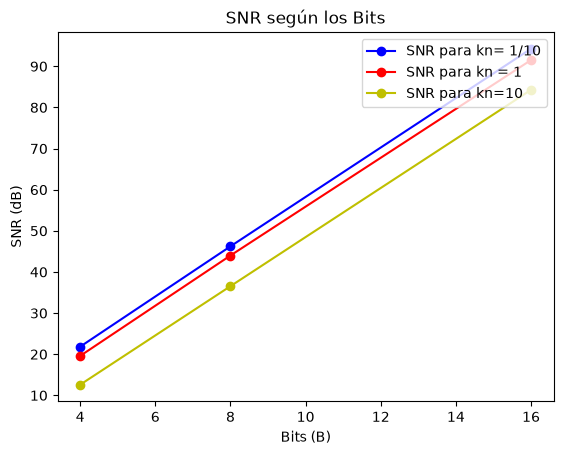

In [15]:
snr01=[]
snr1=[]
snr10=[]
print(f"  B  |  kn  |paso cuantizacón|ruido teorico |ruido medido |SNR teorico |SNR medido | p-valor")
for i in range(len(resultados)):
    if resultados[i]['kn'] == 1/10:
        snr01.append(resultados[i]['snr_medido_dB'])
    elif resultados[i]['kn'] == 1:
        snr1.append(resultados[i]['snr_medido_dB'])
    else:
        snr10.append(resultados[i]['snr_medido_dB'])
    res = resultados[i]
    b = res['B']
    kn = res['kn']
    q = res['q']
    pq = res['Pq_teorico']
    pe = res['Pe_cuant']
    snr_t = res['snr_teorico_dB']
    snr_m = res['snr_medido_dB']
    p_val = res['p_valor']
    print(f"{b:<4} | {kn:<5}|    {q:<8.4f}    | {pq:<10.3e}   | {pe:<10.3e}  | {snr_t:<9.3f}  | {snr_m:<9.3f} | {p_val:<8.4f}")
    

plt.figure()
plt.plot(B, snr01, marker='o', linestyle='-', color='b', label='SNR para kn= 1/10')
plt.plot(B, snr1, marker='o', linestyle='-', color='r', label='SNR para kn = 1')
plt.plot(B, snr10, marker='o', linestyle='-', color='y', label='SNR para kn=10')
plt.legend(loc='upper right')
plt.xlabel('Bits (B)')
plt.ylabel('SNR (dB)')
plt.title('SNR según los Bits')
plt.show()


**ANÁLISIS DE LOS RESULTADOS**

***Ejercicio a)***  (B= 4, kn=1)

Graficamente, se puede observar que tanto la señal con ruido y la salida del ADC es mas bien groera en lugar de lisa, lo cual se debe a que el paso de cuantización, con B= 4 es $q = \frac{4}{2^4} = 0.25$, por lo cual la señal de salida solo puede tomar 16 valores discretos entre -2V y +2V y cada escalón tiene una altura de 0.25V, lo cual es muy grande comparado con la amplitud de la señal. Sin embargo, al tener kn=1, se agrega ruido analógico con la misma potencia que el ruido de cuantización, lo cual aleatoriza el error, por lo cual al realizar el análisis del p-valor no se puede rechazar la hipotesis nula y en el gráfico de la autocorrelación se observa un pico aislado, mostrando que el ruido de cuantización no tiene un comportamiento periódico si no que sigue una distribuición aletoria. El análisis dela DFT muestra que la senoidal con ruido posee un pico en f tal como se esperaba, y luego se comporta como una señal aleatoria para las demas frecuencias. Por su parte, el ruido de cuantización "sigue" la aletoreidad de la DFT de la senoidal con ruido, sin tener ningun pico marcado. Además como kn = 1 los pisos de ruido analógico y digitales no se separan ya que son de la misma magnitud. Por último, comprando los valores teóricos con los medidos estos son muy similares. 


***Ejercico b) y bonus***

Los resultados obtenidos se imprimieron en una tabla para poder compararlos entre si, además de las comparaciones graficas

*Variación de B con kn fijo*

Al mantener kn fijo y solo variar B se puede observar un salto aproximadamente 24dB al pasar de 4 a 8 bits y un salto de 48dB al pasar de 8 a 16 bits. Esto se condice con el incremeto teórico de 6dB por cada bit adicional. Además en el gráfico del SNR segun B se puede observar que su pendiente no depende de kn si no unicamente de B, mostrando un comportamiento lineal.

*Variación de kn con B fijo*

En el caso de B fijo, al variar kn se pude observar que un aumeto de este se reduce el SNR. Además, a mayor kn, mayor es el p-valor obtenido, es decir mas consistente con una distribuición uniforme, mostrando así la función del ruido analógico añadido como decorrelador. Sin embargo, en casos como el de B= 8 y kn = 0.1 se puede observar que a pesar de que el test estadístico da un p-valor de 0.0799 (no rechazando asi la hipotesis nula), en el gráfico de autocorrelación se pueden observar picos periódicos en aproximadamente +/-500 muestras. Esto demuestra que la uniformidad y la incorrelación temporal son independientes, es decir que, a pesar de que el error pueda tener una distribuición uniforme puede no comportarse como ruido blanco. En el caso puntual analizado esto se debe a que el ruido analógico añadido a la señal es insuficiente para "desarmar" la periodicidad generada por una senoidal sobre su propio ruido de cuantización. 

Cuando kn es 0.1 se puede observar ya en el grafico en el dominio temporal para B=4 como, al la señal de entrada no tener suficiente ruido adicionado, la señal del salida del ADC posee picos de error organizados, pudiendose observar la falta de aletoreidad e incorrelación que luego se comprueba mediante el analisis estadistico y el grafico de autocorrelación. Asi mismo el grafico de la FFT para este caso muestra como la DFT del ruido de cuantización presenta una concentración de su sus frecuencias alrededor de la frecuencia correspondiente a la senoidal. Para los otros dos casos no se ve tan claramente como la salida del ADC no corresponde a ruido blanco al ver el grafico temporal debido a que el paso de cuantizacion es mucho mas pequeño. Sin embargo, al observar el grafico de la autocorrelación si se puden observar claros picos periodicos mostrando una falta de icorrelcion del ruido. Además, a pesar de que para B=8 y B= 16 no hay una razon matemática para que el ruido de cuantización del segundo se comparte peor al del primero, el test KS rechaza uniformidad para B=16 (p-valor=0.0304) pero no para B=8 (p-valor=0.0799), se asume que se debe a la secuencia puntual de ruido generada (que al usar la "semilla" de np.random es siempre la misma) , más que de un efecto debido a B. 

Por su parte, cuando kn es 10, es decir el ruido analógico añadido es un orden de magnitud más grande que el ruido de cuantización, tanto los analísis estadísticos como la autocorrelación demuestran que este error de cuantización se corresponde a un ruido uniforme blanco. Sin embargo, este exceso de ruido analógico “empeora” la salida del ADC en el dominio temporal, donde graficamente se observa un señal mas ruidosa de lo necesario.

Por último, para kn=1, se lo puede considerar como un caso más ideal de los tres, ya que, (salvo para el caso B=4), con este kn, tanto los tests estadísticos como gráfico de autocorrección, se corresponden con ruido uniforme blanco, y, a su vez, la salida del ADC es una salida relativamente limpia, donde se puede observar, claramente la señal senoidal. Para el caso de B=cuatro, ocurre algo similar a lo que ocurría con el caso de B=8 y kn=0.1 dónde a pesar de qué el Test estadístico lo describe como una secuencia aleatoria uniforme al observar el gráfico del auto correlación se pueden observar dos pequeños picos aproximadamente en +/-250 muestras. Esto se debe a que para un conversor de tan pocos bits, como el paso de cuantizaión es tan grande en relación a la amplitud de la señal, se requiere añadirle mucho más ruido analógico a la señal para icorrelacionar el ruido de la señal de cuantizacion

**CONCLUSIÓN**

A partir los resultados obtenidos para diferentes B y kn se puede observar la importancia del ruido analogico que se le añade a la señal antes de entrar al ADC, ya que este perimite que al cuantizar la señal, el error añadido sea aleatorio e incorrelado. Esto es importante, ya que, que cuando el error de cuantización no se comporta como ruido blanco sino que se concentra en armónicos de la señal, esos picos resultan indistinguibles de componentes armónicas reales que pudiera tener la señal analógica original. Esto dificulta la interpretación del contenido espectral real de una señal cuando la resolución del ADC o el nivel de ruido añadido son insuficientes.

A su vez se puede ver que hay un relación inversa entre la estadística del error deseada (mejor con más ruido analógico añadido) y fidelidad de la señal reconstruida (peor con más ruido analógico añadido), porque el ruido que se agrega a la señal, aunque estadísticamente "ayuda" a que el error de cuantización se comporte como ruido blanco, sigue siendo ruido que se suma a la señal real y reduce el SNR medido. Por esto se debe elegir un kn acorde que balancee ambos comportamientos

